# สำรวจข้อมูล NSL-KDD (Exploratory Data Analysis)

Notebook นี้สำรวจชุดฝึก `KDDTrain+` ก่อนเริ่มทำความสะอาดและสร้างโมเดล จุดประสงค์คือทำความเข้าใจว่าแต่ละแถวมีลักษณะอย่างไร ข้อมูลมีปัญหาคุณภาพหรือไม่ การโจมตีชนิดใดพบมาก และตัวแปรมีการกระจายแบบไหน เพื่อใช้ตัดสินใจออกแบบ preprocessing และวิธีประเมินโมเดลอย่างมีเหตุผล

โค้ดจะอ่านข้อมูลดิบ 125,973 แถว 43 คอลัมน์ แล้วสร้างตารางสรุป กราฟ และการเปรียบเทียบระหว่างทราฟฟิกปกติกับทราฟฟิกโจมตี ค่าที่แสดงในแต่ละส่วนเป็นผลสำรวจ ไม่ได้เปลี่ยนไฟล์ต้นทางและยังไม่ใช่ผลการเทรนโมเดล

แนวทางอ่านผล: ดูทั้งจำนวนแถวและเปอร์เซ็นต์ เพราะคลาสที่พบน้อยอาจถูกซ่อนเมื่อดูเฉพาะจำนวนรวม; ดูกราฟร่วมกับตารางสถิติ; และแยกให้ออกระหว่างค่าผิดปกติทางสถิติกับข้อมูลผิดจริง เพราะพฤติกรรมโจมตีที่น่าสนใจอาจมีค่าห่างจากทราฟฟิกทั่วไป

ผลสำคัญที่ notebook จะช่วยตอบ ได้แก่ ข้อมูลฝึกมี missing/duplicate หรือไม่, label ใดครองสัดส่วน, ตัวเลขใดมีศูนย์จำนวนมากหรือหางยาว, และคุณลักษณะใดแตกต่างกันระหว่าง normal กับ attack ข้อสังเกตเหล่านี้เป็นสมมติฐานสำหรับขั้นถัดไป ไม่ใช่หลักฐานเชิงเหตุและผล

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

In [2]:
columns = [
    "duration",
    "protocol_type",
    "service",
    "flag",
    "src_bytes",
    "dst_bytes",
    "land",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "logged_in",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "is_host_login",
    "is_guest_login",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "label",
    "difficulty",
]

def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "dataset" / "download_nsl_dataset.py").is_file() and (candidate / "data-pipeline").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the CSI_ML_Final project root from the current working directory.")

PROJECT_ROOT = find_project_root(Path.cwd())
data_path = PROJECT_ROOT / "dataset" / "rawdata" / "NSL-KDD" / "KDDTrain+.txt"
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path.resolve()}")

df = pd.read_csv(data_path, names=columns)
df["label"] = df["label"].astype(str).str.strip().str.lower()

print(f"Loaded: {data_path.relative_to(PROJECT_ROOT)}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.head())

Loaded: dataset\rawdata\NSL-KDD\KDDTrain+.txt
Shape: 125,973 rows x 43 columns


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.000,0.000,0.000,0.000,1.000,0.000,0.000,150,25,0.170,0.030,0.170,0.000,0.000,0.000,0.050,0.000,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.000,0.000,0.000,0.000,0.080,0.150,0.000,255,1,0.000,0.600,0.880,0.000,0.000,0.000,0.000,0.000,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.000,1.000,0.000,0.000,0.050,0.070,0.000,255,26,0.100,0.050,0.000,0.000,1.000,1.000,0.000,0.000,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.200,0.200,0.000,0.000,1.000,0.000,0.000,30,255,1.000,0.000,0.030,0.040,0.030,0.010,0.000,0.010,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.000,0.000,0.000,0.000,1.000,0.000,0.090,255,255,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,normal,21


## 1. ภาพรวมชุดข้อมูลและคุณภาพข้อมูล

ตารางแรกสรุปจำนวนแถว/คอลัมน์ จำนวนแถวซ้ำ จำนวนช่องว่าง และหน่วยความจำที่ใช้ ส่วนตาราง missing แสดงเฉพาะคอลัมน์ที่มีค่าว่าง และรายการ constant แสดงคอลัมน์ที่มีค่าเดียวตลอดทั้งชุด

ผลที่พบในชุดฝึกนี้คือ 125,973 แถว 43 คอลัมน์ ไม่มี missing และไม่มีแถวซ้ำแบบตรงกันทุกคอลัมน์ แต่ `num_outbound_cmds` เป็นค่าคงที่ทั้งหมด จึงไม่มีข้อมูลช่วยแยกตัวอย่าง โมเดลมักไม่ได้ประโยชน์จากคอลัมน์เช่นนี้ และขั้น cleansing จะตัดออกภายหลัง ส่วน `difficulty` เป็น metadata ของ benchmark ซึ่งต้องระวังไม่ให้ปะปนเป็น feature ที่ใช้ทำนาย

In [3]:
categorical_cols = ["protocol_type", "service", "flag"]
numeric_cols = [col for col in df.columns if col not in categorical_cols + ["label"]]

overview = pd.DataFrame({
    "rows": [len(df)],
    "columns": [df.shape[1]],
    "duplicate_rows": [df.duplicated().sum()],
    "missing_cells": [df.isna().sum().sum()],
    "memory_mb": [df.memory_usage(deep=True).sum() / 1024**2],
})
display(overview)

missing_table = (
    df.isna()
      .sum()
      .rename("missing")
      .to_frame()
      .assign(missing_pct=lambda x: x["missing"] / len(df) * 100)
      .query("missing > 0")
      .sort_values("missing", ascending=False)
)

if missing_table.empty:
    print("Missing-value check: no missing values found.")
else:
    display(missing_table)

constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) <= 1]
print(f"Constant columns ({len(constant_cols)}): {constant_cols}")

,rows,columns,duplicate_rows,missing_cells,memory_mb
0,125973,43,0,0,63.081


Missing-value check: no missing values found.
Constant columns (1): ['num_outbound_cmds']


## 2. สร้างกลุ่มประเภทการโจมตีและ target สำหรับการสำรวจ

`label` เดิมระบุชื่อการโจมตีรายชนิด เช่น `neptune` หรือ `ipsweep` โค้ดจึง map ชื่อที่รู้จักไปเป็น 4 กลุ่มมาตรฐาน: DoS (ทำให้บริการหยุดชะงัก), Probe (สำรวจเครื่อง/พอร์ต), R2L (บุคคลภายนอกพยายามเข้าถึงบัญชีในเครื่อง) และ U2R (ผู้ใช้ยกระดับสิทธิ์) แถว `normal` ถูกจัดเป็น Normal ส่วนชื่อที่ไม่อยู่ใน mapping จะเป็น Unknown เพื่อไม่เดาประเภทเอง

สร้าง `is_attack` เพิ่มเป็น 0 เมื่อ label เป็น normal และ 1 สำหรับ label อื่นทั้งหมด ตารางแรกแสดงจำนวนและเปอร์เซ็นต์แยกตาม family ตารางที่สองแสดง label รายตัว 20 อันดับแรก ผลใน KDDTrain คือ Normal 67,343 แถว (53.46%), DoS 45,927 (36.46%), Probe 11,656 (9.25%), R2L 995 (0.79%) และ U2R 52 (0.04%); ไม่พบ label การโจมตีที่ map ไม่ได้ในชุดฝึก

ความหมายเชิงโมเดล: family-level ทำให้เห็นภาพกว้าง แต่การรวมกลุ่มทำให้ความแตกต่างระหว่างการโจมตีรายชนิดหายไป และ U2R/R2L มีตัวอย่างน้อยมาก จึงต้องใช้ metric ที่เหมาะกับคลาสหายากในงาน supervised ภายหลัง ทั้ง `attack_family` และ `is_attack` เป็นป้ายกำกับสำหรับวิเคราะห์/ประเมิน ไม่ใช่ feature ที่ควรป้อนเข้า Isolation Forest แบบ unsupervised

In [4]:
attack_family_map = {
    # Denial of Service
    "back": "DoS",
    "land": "DoS",
    "neptune": "DoS",
    "pod": "DoS",
    "smurf": "DoS",
    "teardrop": "DoS",

    # Probe
    "ipsweep": "Probe",
    "nmap": "Probe",
    "portsweep": "Probe",
    "satan": "Probe",

    # Remote to Local
    "ftp_write": "R2L",
    "guess_passwd": "R2L",
    "imap": "R2L",
    "multihop": "R2L",
    "phf": "R2L",
    "spy": "R2L",
    "warezclient": "R2L",
    "warezmaster": "R2L",

    # User to Root
    "buffer_overflow": "U2R",
    "loadmodule": "U2R",
    "perl": "U2R",
    "rootkit": "U2R",
}

df["attack_family"] = df["label"].map(attack_family_map)

normal_mask = (
    df["attack_family"].isna()
    & df["label"].eq("normal")
)

df.loc[normal_mask, "attack_family"] = "Normal"
df["attack_family"] = df["attack_family"].fillna("Unknown")
df["is_attack"] = df["label"].ne("normal").astype(int)

label_summary = (
    df["label"]
      .value_counts()
      .rename_axis("label")
      .reset_index(name="rows")
      .assign(percent=lambda x: x["rows"] / len(df) * 100)
)
family_summary = (
    df["attack_family"]
      .value_counts()
      .rename_axis("attack_family")
      .reset_index(name="rows")
      .assign(percent=lambda x: x["rows"] / len(df) * 100)
)

display(family_summary)
display(label_summary.head(20))
print("Unmapped non-normal labels:", sorted(df.loc[(df["attack_family"] == "Unknown") & (df["label"] != "normal"), "label"].unique()))

,attack_family,rows,percent
0,Normal,67343,53.458
1,DoS,45927,36.458
2,Probe,11656,9.253
3,R2L,995,0.790
4,U2R,52,0.041


,label,rows,percent
0,normal,67343,53.458
1,neptune,41214,32.717
2,satan,3633,2.884
3,ipsweep,3599,2.857
4,portsweep,2931,2.327
5,smurf,2646,2.100
6,nmap,1493,1.185
7,back,956,0.759
8,teardrop,892,0.708
9,warezclient,890,0.707


Unmapped non-normal labels: []


## 3. สัดส่วนคลาสและความไม่สมดุล

กราฟซ้ายเปรียบเทียบเปอร์เซ็นต์ของ Normal และแต่ละ attack family; กราฟขวาแสดงจำนวนของ label รายตัวที่พบบ่อย 15 อันดับ แกนและหน่วยต่างกัน: กราฟซ้ายเป็นเปอร์เซ็นต์ ส่วนกราฟขวาเป็นจำนวนแถว

ในข้อมูลนี้ทราฟฟิกปกติมีประมาณ 53.46% และการโจมตีรวมประมาณ 46.54% แต่การโจมตีไม่ได้กระจายเท่า ๆ กัน: DoS เป็นกลุ่มใหญ่ที่สุด และ label `neptune` เพียงชนิดเดียวมี 41,214 แถว ขณะที่บางชนิดมีเพียงหลักหน่วยหรือหลักสิบ นี่คือ class imbalance ระดับ label/family ซึ่งอาจทำให้การวัด accuracy อย่างเดียวดูดีเกินจริงและทำให้โมเดลมองข้ามคลาสหายาก

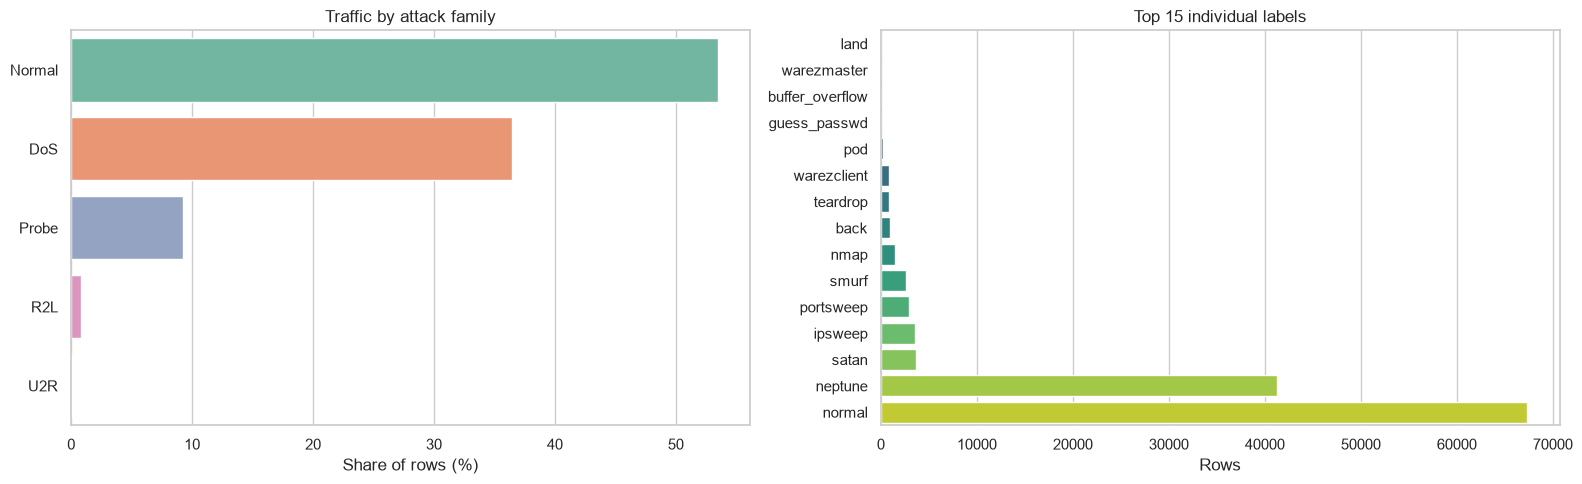

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

family_order = ["Normal", "DoS", "Probe", "R2L", "U2R", "Unknown"]
family_plot = family_summary.set_index("attack_family").reindex(family_order).dropna().reset_index()
sns.barplot(
    data=family_plot,
    x="percent",
    y="attack_family",
    hue="attack_family",
    palette="Set2",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Traffic by attack family")
axes[0].set_xlabel("Share of rows (%)")
axes[0].set_ylabel("")

top_labels = label_summary.head(15).sort_values("rows")
sns.barplot(
    data=top_labels,
    x="rows",
    y="label",
    hue="label",
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Top 15 individual labels")
axes[1].set_xlabel("Rows")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 4. สำรวจตัวแปรเชิงหมวดหมู่

กราฟสามช่องนับค่าที่พบบ่อยของ `protocol_type`, `service` และ `flag` โดยแสดงได้ไม่เกิน 12 หมวดต่อช่องเพื่อให้อ่านง่าย ตารางด้านล่างนับจำนวนหมวดที่แตกต่างกันทั้งหมด: protocol มี 3, flag มี 11 และ service มี 70 ค่า

ผลนี้บอกว่า `service` มี cardinality สูงกว่าตัวแปรหมวดหมู่อื่นมาก จึงต้องแปลงเป็นตัวเลขก่อนป้อนโมเดล เช่น One-Hot Encoding โดยสร้าง vocabulary จาก train และใช้ schema เดียวกันกับ test; หมวดที่ไม่เคยพบใน train ต้องรายงานและจัดการอย่างชัดเจน การที่หมวดหนึ่งพบมากไม่ได้แปลว่าหมวดนั้นเป็นการโจมตีโดยตัวมันเอง

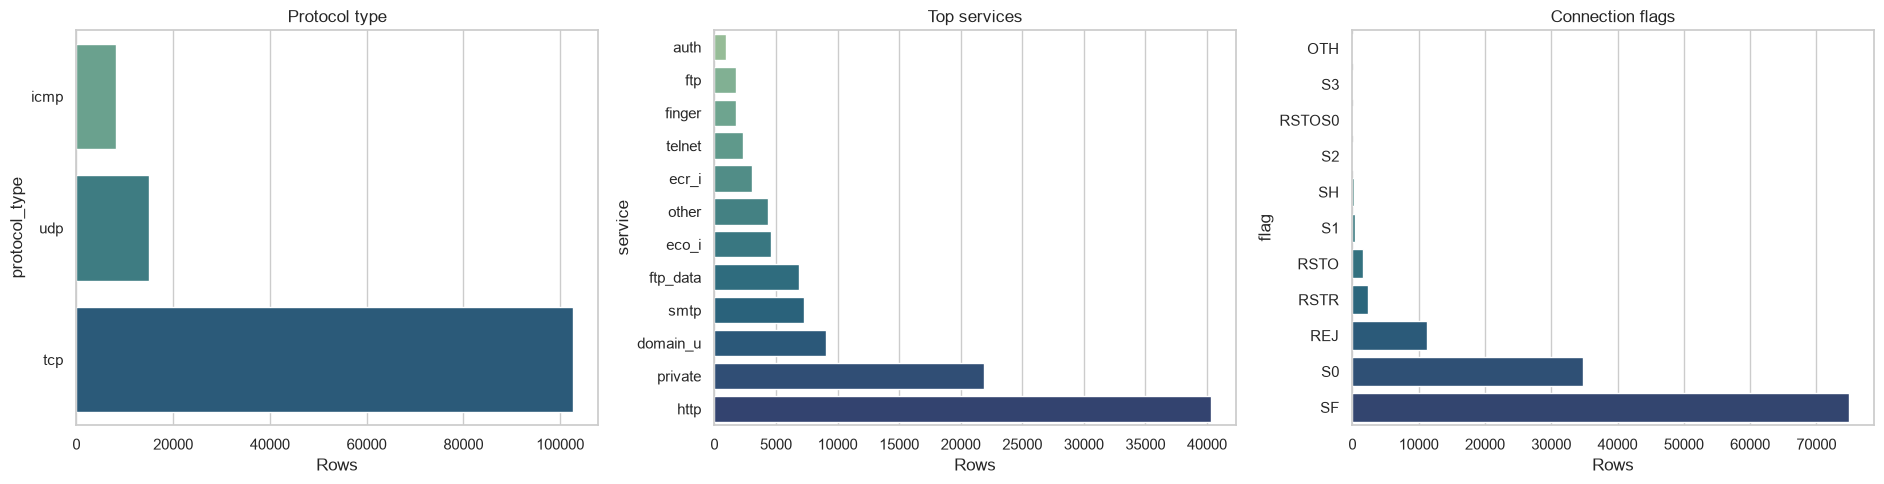

,unique_values
service,70
flag,11
protocol_type,3


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, col, title in zip(
    axes,
    categorical_cols,
    ["Protocol type", "Top services", "Connection flags"],
):
    counts = df[col].value_counts().head(12).sort_values()
    sns.barplot(
        x=counts.values,
        y=counts.index,
        hue=counts.index,
        palette="crest",
        legend=False,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Rows")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

categorical_cardinality = (
    df[categorical_cols]
      .nunique()
      .rename("unique_values")
      .to_frame()
      .sort_values("unique_values", ascending=False)
)
display(categorical_cardinality)

## 5. สถิติตัวเลข คอลัมน์ที่เป็นศูนย์บ่อย และค่าปลายหาง

ตาราง `describe()` แสดงจำนวนค่าที่ใช้คำนวณ ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ควอไทล์ และค่าสูงสุด; เพิ่ม `n_unique` เพื่อดูจำนวนค่าที่แตกต่าง, `zero_pct` เพื่อดูเปอร์เซ็นต์ที่เป็นศูนย์ และ `skew` เพื่อบอกความเบ้ของการกระจาย ค่า skew บวกสูงมักหมายถึงข้อมูลส่วนใหญ่อยู่ค่าต่ำแต่มีหางยาวไปทางค่าสูง

คอลัมน์ศูนย์สูงสุดคือ `num_outbound_cmds` (100% และมีค่าเดียว), ตามด้วย `is_host_login` (99.999%), `urgent` (99.993%) และตัวชี้วัดเหตุการณ์ที่พบยากอื่น ๆ ค่าศูนย์มากไม่ได้แปลว่าคอลัมน์ไร้ประโยชน์เสมอไป เพราะค่าไม่เป็นศูนย์อาจเป็นสัญญาณสำคัญ; แต่คอลัมน์ที่คงที่จริงไม่มีความสามารถแยกแถว

ตาราง outlier ใช้กฎ IQR: ค่าน้อยกว่า Q1−1.5×IQR หรือมากกว่า Q3+1.5×IQR จะถูกนับเป็น outlier เช่น `dst_bytes` ประมาณ 18.72% การนับนี้เป็นเพียงเกณฑ์สถิติ ไม่ใช่การยืนยันว่าค่าผิดหรือควรถูกลบทิ้ง สำหรับ network intrusion ค่า extreme อาจเป็นพฤติกรรมโจมตีจริง จึงควรตรวจบริบทและเลือกวิธีแปลง/scale แทนการตัดอัตโนมัติ

In [7]:
numeric_summary = df[numeric_cols].describe().T
numeric_summary["n_unique"] = df[numeric_cols].nunique()
numeric_summary["zero_pct"] = (df[numeric_cols].eq(0).mean() * 100)
numeric_summary["skew"] = df[numeric_cols].skew()
numeric_summary = numeric_summary[
    ["count", "n_unique", "mean", "std", "min", "25%", "50%", "75%", "max", "zero_pct", "skew"]
]

display(numeric_summary.round(3))

print("Features with the highest percentage of zero values:")
display(
    numeric_summary[["n_unique", "zero_pct"]]
    .sort_values("zero_pct", ascending=False)
    .head(12)
    .round(3)
)

,count,n_unique,mean,std,min,25%,50%,75%,max,zero_pct,skew
duration,"125,973.000",2981,287.145,"2,604.515",0.000,0.000,0.000,0.000,"42,908.000",92.048,11.880
src_bytes,"125,973.000",3341,"45,566.743","5,870,331.182",0.000,0.000,44.000,276.000,"1,379,963,888.000",39.208,190.669
dst_bytes,"125,973.000",9326,"19,779.114","4,021,269.151",0.000,0.000,0.000,516.000,"1,309,937,401.000",53.954,290.053
land,"125,973.000",2,0.000,0.014,0.000,0.000,0.000,0.000,1.000,99.980,70.965
wrong_fragment,"125,973.000",3,0.023,0.254,0.000,0.000,0.000,0.000,3.000,99.135,11.458
urgent,"125,973.000",4,0.000,0.014,0.000,0.000,0.000,0.000,3.000,99.993,149.915
hot,"125,973.000",28,0.204,2.150,0.000,0.000,0.000,0.000,77.000,97.880,12.590
num_failed_logins,"125,973.000",6,0.001,0.045,0.000,0.000,0.000,0.000,5.000,99.903,53.764
logged_in,"125,973.000",2,0.396,0.489,0.000,0.000,0.000,1.000,1.000,60.426,0.426
num_compromised,"125,973.000",88,0.279,23.942,0.000,0.000,0.000,0.000,"7,479.000",98.979,250.108


Features with the highest percentage of zero values:


,n_unique,zero_pct
num_outbound_cmds,1,100.000
is_host_login,2,99.999
urgent,4,99.993
land,2,99.980
num_shells,3,99.963
su_attempted,3,99.936
num_failed_logins,6,99.903
root_shell,2,99.866
num_file_creations,35,99.772
num_access_files,10,99.705


In [8]:
outlier_cols = [
    col for col in numeric_cols
    if col not in {"difficulty"} and df[col].nunique() > 2
]

outlier_rows = []
for col in outlier_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "feature": col,
        "outlier_rows": int(mask.sum()),
        "outlier_pct": mask.mean() * 100,
        "lower_bound": lower,
        "upper_bound": upper,
    })

outlier_summary = (
    pd.DataFrame(outlier_rows)
      .sort_values("outlier_pct", ascending=False)
      .reset_index(drop=True)
)

display(outlier_summary.head(15).round(3))

,feature,outlier_rows,outlier_pct,lower_bound,upper_bound
0,srv_diff_host_rate,28399,22.544,0.000,0.000
1,dst_host_same_src_port_rate,25052,19.887,-0.090,0.150
2,dst_bytes,23579,18.718,-774.000,"1,290.000"
3,dst_host_rerror_rate,22795,18.095,0.000,0.000
4,dst_host_srv_rerror_rate,19357,15.366,0.000,0.000
5,srv_rerror_rate,16206,12.865,0.000,0.000
6,rerror_rate,16190,12.852,0.000,0.000
7,src_bytes,13840,10.986,-414.000,690.000
8,srv_count,12054,9.569,-22.000,42.000
9,dst_host_srv_diff_host_rate,11682,9.273,-0.030,0.050


## 6. รูปร่างการกระจายของตัวแปร

ฮิสโตแกรมแสดง `log1p(x)` ของ duration, bytes และ connection counts เพื่อให้เห็นบริเวณค่าต่ำกับหางยาวในรูปเดียวกัน `log1p(x)` คือ `ln(1+x)` จึงแปลงศูนย์ได้และบีบค่ามากให้ห่างกันน้อยลง กราฟนี้ใช้เพื่อสำรวจเท่านั้น ไม่ได้เขียนทับข้อมูลต้นฉบับ

หากกราฟหลังแปลงยังมีหางยาว แปลว่าค่าที่สูงมากยังมีอยู่แต่ถูกบีบสเกลแล้ว; หากส่วนใหญ่กระจุกใกล้ศูนย์ แสดงว่าทราฟฟิกส่วนมากมีปริมาณ/จำนวนต่ำและมีส่วนน้อยที่สูงมาก ขั้น feature engineering จะสร้างคอลัมน์ log1p เพิ่มโดยเก็บค่าต้นฉบับไว้ เพื่อให้ทดลองเปรียบเทียบได้

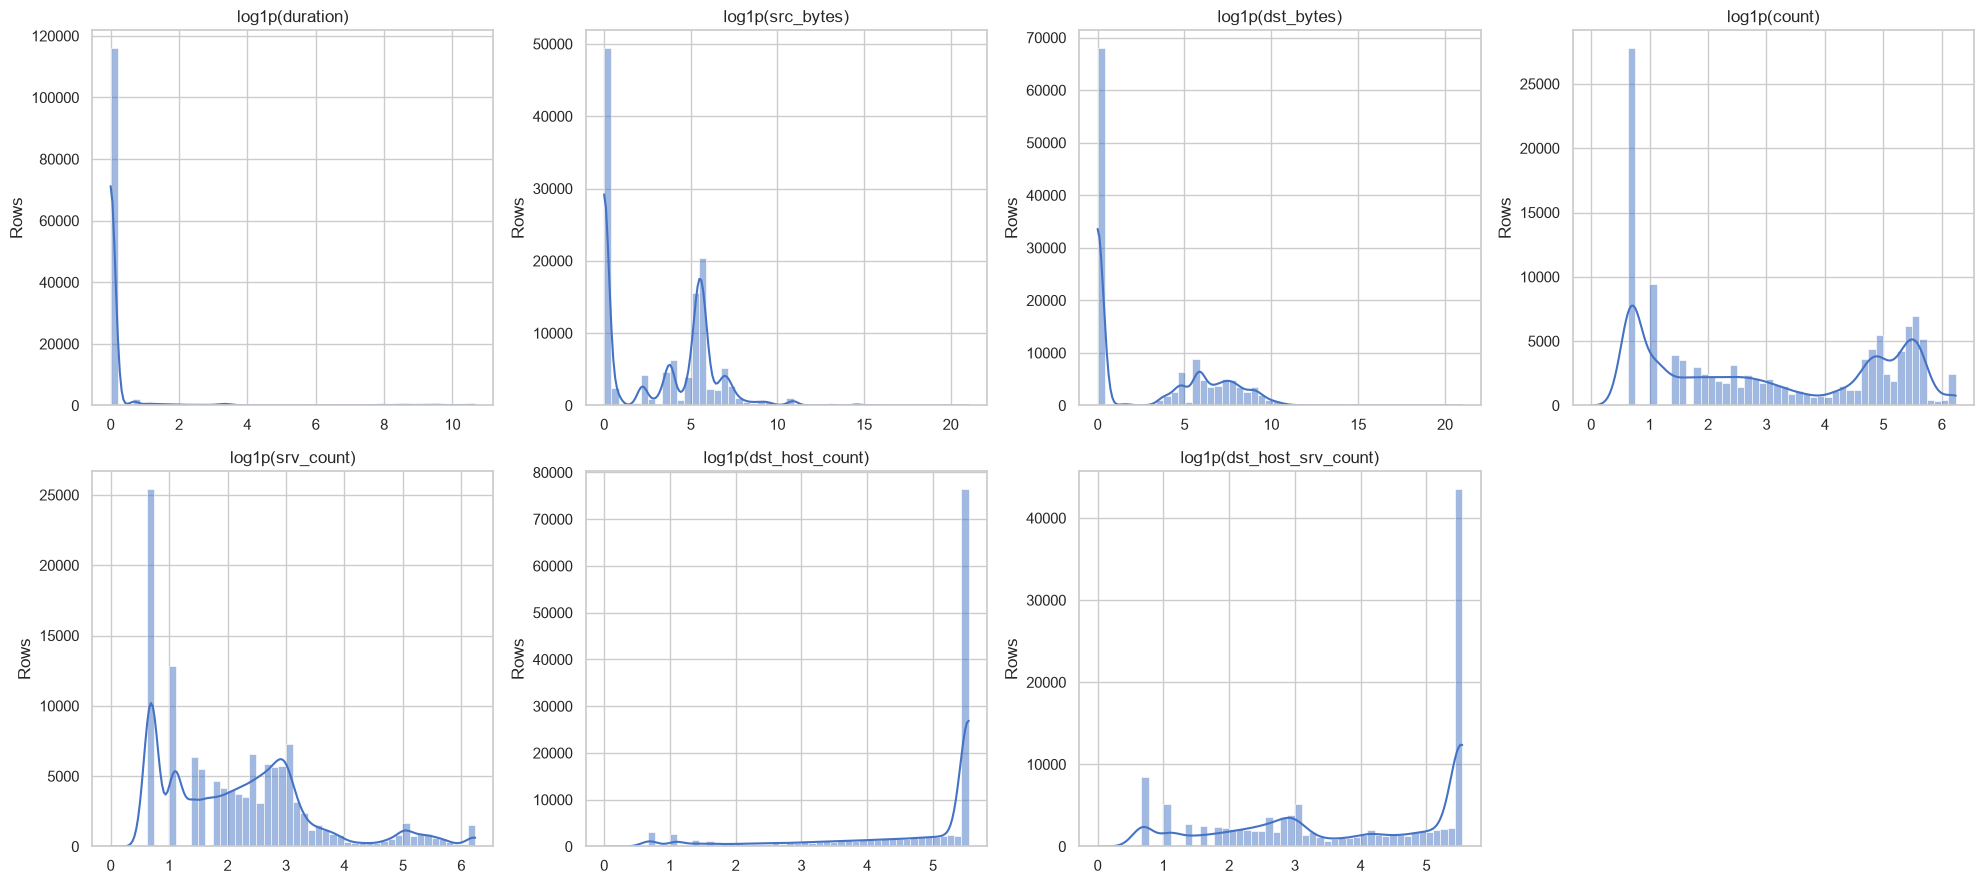

In [9]:
distribution_cols = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "count",
    "srv_count",
    "dst_host_count",
    "dst_host_srv_count",
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, distribution_cols):
    sns.histplot(np.log1p(df[col]), bins=50, kde=True, color="#4472C4", ax=ax)
    ax.set_title(f"log1p({col})")
    ax.set_xlabel("")
    ax.set_ylabel("Rows")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## 7. เปรียบเทียบการโจมตีกับทราฟฟิกปกติ

โค้ดสุ่มตัวอย่างสูงสุด 25,000 แถวด้วย seed 42 เพื่อให้กราฟทำงานเร็วและรันซ้ำได้ แล้ววาด boxplot ของตัวแปร 6 ตัว แกนค่าของ duration/bytes/count ใช้ log1p; ปิดจุด fliers เพื่อไม่ให้จุดจำนวนมากทับกัน แต่ข้อมูลเหล่านั้นไม่ได้ถูกลบจาก DataFrame

อ่านเส้นกลางเป็น median และกล่องเป็นช่วงควอไทล์ 25–75%; หากตำแหน่งหรือความกว้างของกล่องต่างกัน แสดงว่าตัวแปรอาจช่วยแยกกลุ่มได้ แต่ถ้ากล่องซ้อนกันมาก ตัวแปรเดี่ยวอาจแยกได้ไม่ชัด การเปรียบเทียบเป็น exploratory เท่านั้น ไม่พิสูจน์เหตุและผล และรูปแบบที่เห็นอาจเปลี่ยนเมื่อพิจารณาคุณลักษณะหลายตัวร่วมกัน

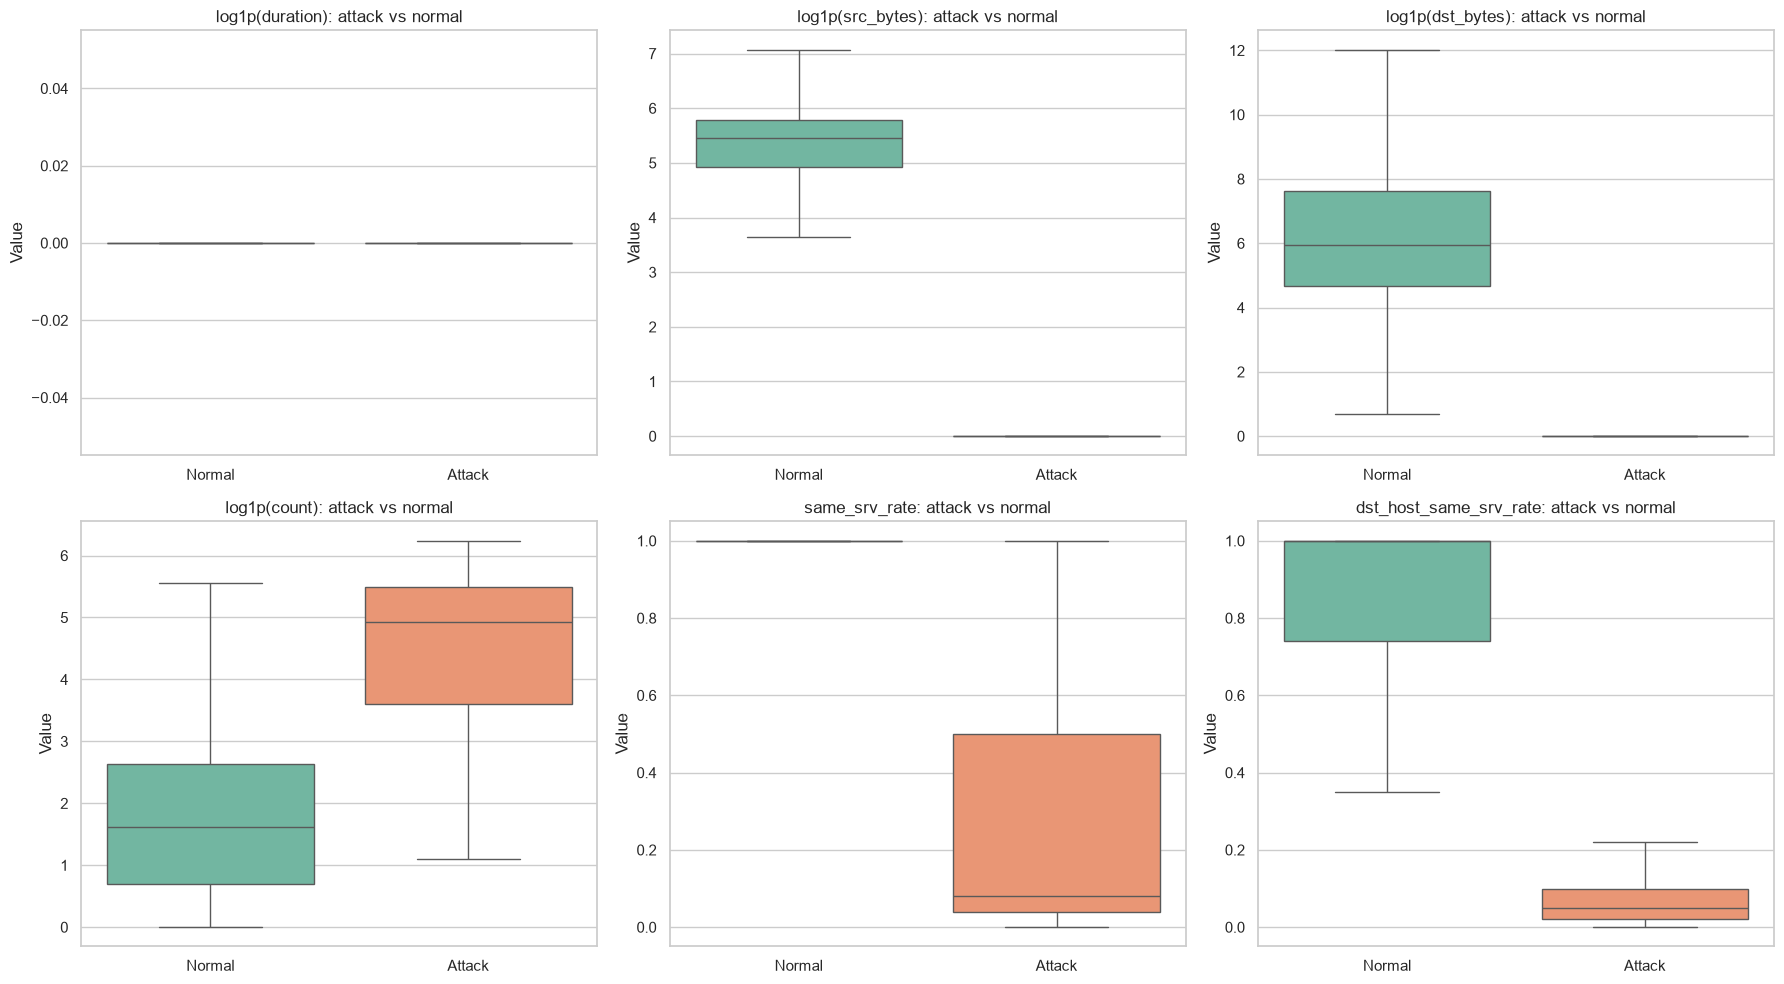

In [10]:
comparison_cols = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "count",
    "same_srv_rate",
    "dst_host_same_srv_rate",
]

plot_df = df[["is_attack"] + comparison_cols].copy()
plot_df["traffic_class"] = np.where(plot_df["is_attack"].eq(1), "Attack", "Normal")
plot_df = plot_df.sample(min(25_000, len(plot_df)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, comparison_cols):
    values = np.log1p(plot_df[col]) if col in {"duration", "src_bytes", "dst_bytes", "count"} else plot_df[col]
    box_data = pd.DataFrame({"traffic_class": plot_df["traffic_class"], "value": values})
    sns.boxplot(
        data=box_data,
        x="traffic_class",
        y="value",
        hue="traffic_class",
        palette={"Normal": "#66c2a5", "Attack": "#fc8d62"},
        legend=False,
        showfliers=False,
        ax=ax,
    )
    plot_title = f"log1p({col})" if col in {"duration", "src_bytes", "dst_bytes", "count"} else col
    ax.set_title(f"{plot_title}: attack vs normal")
    ax.set_xlabel("")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

## 8. ความสัมพันธ์ระหว่างตัวแปรและกับ target

heatmap ใช้ Pearson correlation ระหว่างตัวแปรตัวเลขที่เลือก ค่าใกล้ +1 หมายถึงเคลื่อนไหวไปทิศทางเดียวกัน, ใกล้ −1 คือสวนทางกัน และใกล้ 0 คือไม่มีความสัมพันธ์เชิงเส้นเด่นชัด สีบอกทิศทางและความเข้มบอกขนาดความสัมพันธ์ คู่ที่สัมพันธ์กันสูงอาจมีข้อมูลซ้ำซ้อน แต่ correlation ไม่ได้ยืนยันเหตุและผล

ตารางด้านล่างคำนวณ correlation ของตัวเลขแต่ละตัวกับ `is_attack` แบบตัวแปรต่อหนึ่งตัว ผลเด่นใน train ได้แก่ `same_srv_rate` −0.752, `dst_host_srv_count` −0.723, `dst_host_same_srv_rate` −0.694, `logged_in` −0.690 และ `dst_host_srv_serror_rate` +0.655 ค่าลบหมายถึงในข้อมูลนี้เมื่อ feature สูงขึ้น ค่า is_attack มีแนวโน้มต่ำลงในเชิงเส้น ไม่ได้หมายความว่า feature ทำให้เกิดผลนั้น

คอลัมน์คงที่อย่าง `num_outbound_cmds` ไม่มีส่วนเบี่ยงเบนมาตรฐานและคำนวณ correlation ไม่ได้ จึงไม่นำคอลัมน์คงที่เข้า correlation กับ target; วิธีนี้ป้องกัน RuntimeWarning และค่า NaN ที่ไม่ช่วยการวิเคราะห์ นอกจากนี้ `difficulty` เป็น metadata ของ benchmark แม้สัมพันธ์กับ target ก็ไม่ควรรีบใช้เป็น feature เพราะอาจทำให้การประเมินไม่สะท้อนการตรวจจับจาก traffic จริง

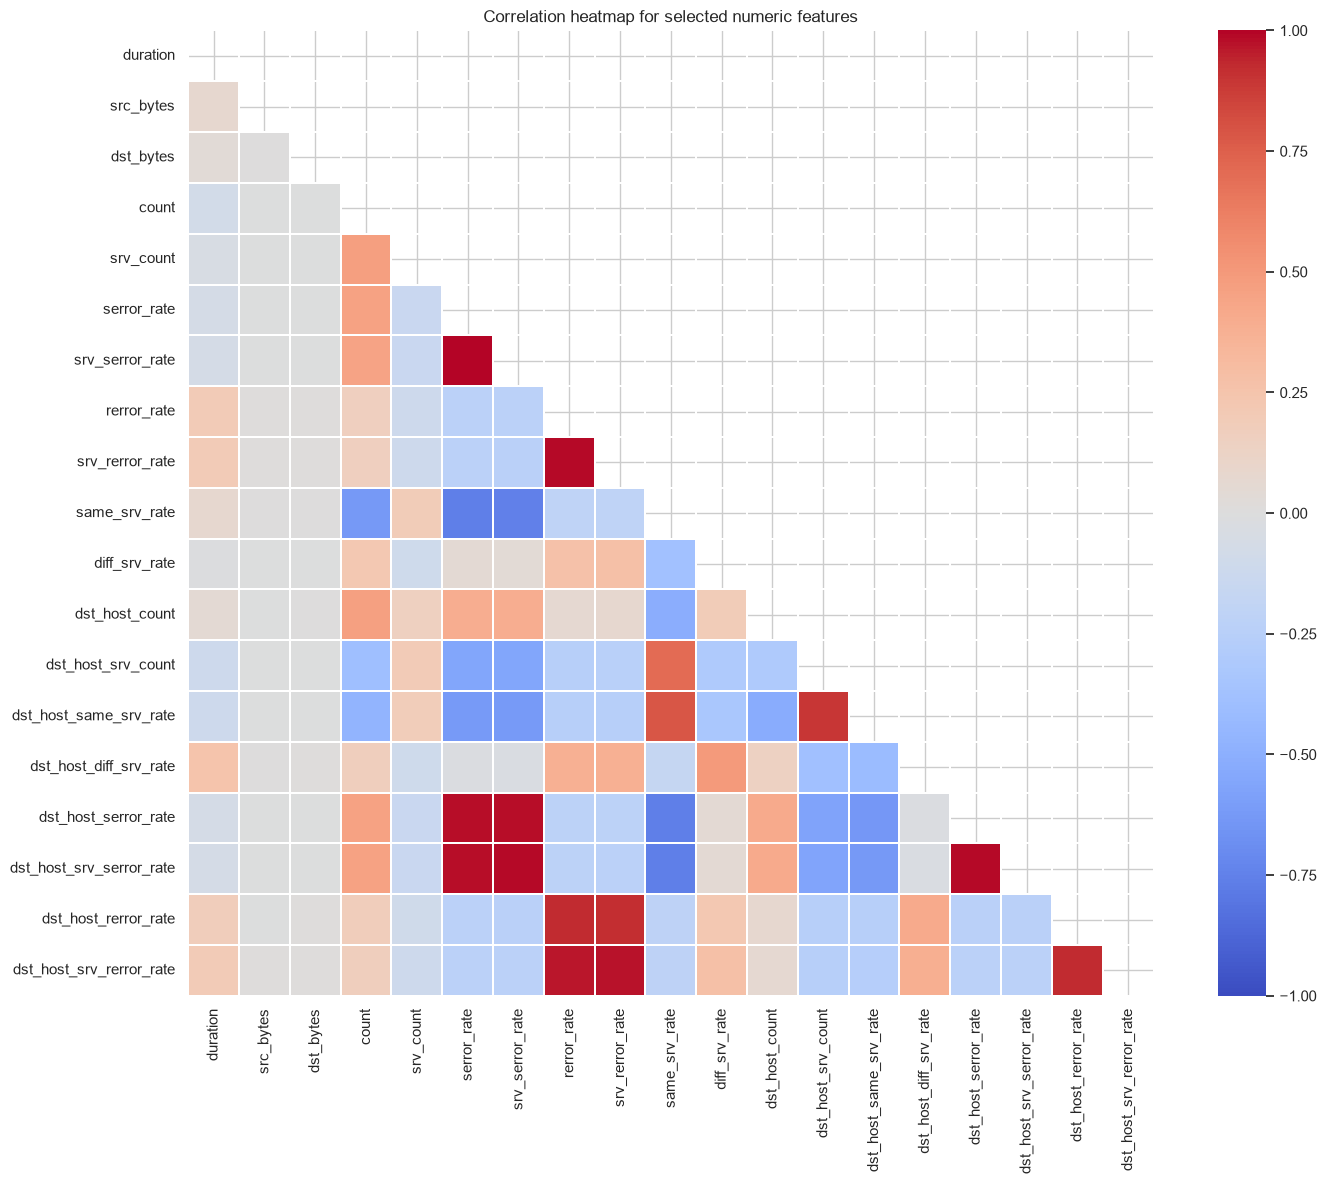

,corr_with_is_attack,abs_corr
same_srv_rate,-0.752,0.752
dst_host_srv_count,-0.723,0.723
dst_host_same_srv_rate,-0.694,0.694
logged_in,-0.690,0.690
dst_host_srv_serror_rate,0.655,0.655
dst_host_serror_rate,0.652,0.652
serror_rate,0.651,0.651
srv_serror_rate,0.648,0.648
count,0.576,0.576
difficulty,-0.380,0.380


In [11]:
correlation_cols = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
]

corr = df[correlation_cols].corr()

plt.figure(figsize=(15, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.25,
)
plt.title("Correlation heatmap for selected numeric features")
plt.tight_layout()
plt.show()

association_cols = [
    col for col in numeric_cols
    if col != "is_attack" and df[col].nunique(dropna=False) > 1
]
target_association = (
    df[association_cols]
      .corrwith(df["is_attack"])
      .to_frame("corr_with_is_attack")
)
target_association["abs_corr"] = target_association["corr_with_is_attack"].abs()
target_association = target_association.sort_values("abs_corr", ascending=False)

display(target_association.head(15).round(3))

## 9. ข้อสรุปที่นำไปใช้กับการทำโมเดล

เซลล์ถัดไปสรุปตัวเลขจาก DataFrame โดยตรง: ขนาดข้อมูล, attack share, family ที่ใหญ่ที่สุด, missing/duplicate, ตัวแปรศูนย์สูง และตัวแปรเบ้สูง ผลที่ได้คือ 125,973 แถว, attack 46.54%, normal 53.46%, ไม่มี missing/duplicate และ DoS เป็น family ใหญ่สุดในบรรดากลุ่มโจมตี

ข้อเสนอจาก EDA: encode protocol/service/flag; พิจารณา log1p หรือ robust scaling สำหรับตัวเลขหางยาว; อย่าลบค่าปลายหางโดยอัตโนมัติ; ประเมิน precision/recall และผลแยกตามคลาสแทน accuracy อย่างเดียว; และไม่ป้อน `label`, `attack_family`, `is_attack` หรือ metadata `difficulty` เข้าโมเดล unsupervised การสำรวจนี้เป็นจุดเริ่มตั้งสมมติฐาน ซึ่งควรยืนยันด้วย validation ที่แยกจากชุดทดสอบ

In [12]:
dominant_family = family_summary.iloc[0]
attack_share = df["is_attack"].mean() * 100
high_zero_features = numeric_summary.sort_values("zero_pct", ascending=False).head(5).index.tolist()
high_skew_features = numeric_summary.assign(abs_skew=numeric_summary["skew"].abs()).sort_values(
    "abs_skew", ascending=False
).head(5).index.tolist()

print(f"- Dataset size: {len(df):,} rows and {df.shape[1] - 2} original columns.")
print(f"- Attack traffic: {attack_share:,.2f}% of rows; normal traffic: {100 - attack_share:,.2f}%.")
print(f"- Largest family: {dominant_family['attack_family']} ({dominant_family['percent']:,.2f}% of rows).")
print(f"- Missing values: {int(df.isna().sum().sum())}; duplicate rows: {int(df.duplicated().sum())}.")
print(f"- Zero-heavy features: {', '.join(high_zero_features)}.")
print(f"- Most right-skewed features: {', '.join(high_skew_features)}.")
print("- Modeling notes: encode protocol/service/flag, consider log1p or robust scaling for heavy-tailed traffic features,")
print("  preserve the attack/normal imbalance in evaluation, and treat 'difficulty' as dataset metadata unless there is")
print("  a specific reason to include it as a predictive feature.")

- Dataset size: 125,973 rows and 43 original columns.
- Attack traffic: 46.54% of rows; normal traffic: 53.46%.
- Largest family: Normal (53.46% of rows).
- Missing values: 0; duplicate rows: 0.
- Zero-heavy features: num_outbound_cmds, is_host_login, urgent, land, num_shells.
- Most right-skewed features: is_host_login, dst_bytes, num_compromised, num_root, src_bytes.
- Modeling notes: encode protocol/service/flag, consider log1p or robust scaling for heavy-tailed traffic features,
  preserve the attack/normal imbalance in evaluation, and treat 'difficulty' as dataset metadata unless there is
  a specific reason to include it as a predictive feature.
